# Prophet Lookahead Audit: Investigating Data Leakage across Billing Cycles

### Context & Research Question
In `prophet_burn_rate.ipynb`, Prophet was fit per `(sim_id, billing_cycle_num)` group, generating one end-of-cycle summary forecast stored in `prophet_features.parquet`. Subsequently, `xgboost_triage.ipynb` merged this single forecast per billing cycle onto all daily rows of that cycle via a broadcast left join on `['sim_id', 'billing_cycle_num']`.

If a forecast was fit using all observed days of a billing cycle (including days late in the cycle), copying that forecast backward onto early days of the cycle could carry information from future days into early-cycle scoring. 

This notebook empirically audits and measures whether lookahead leakage occurred using:
1. **A Controlled Experiment**: Comparing `FULL` vs `EARLY` (< day 10) fits on `LATE` anomaly episodes vs clean `CONTROL` cycles.
2. **An Early-Rows Predictive Test**: Training XGBoost on daily rows with `day_in_cycle < 7` to test whether Prophet features predict anomalies before a legitimate forecast could exist.


## 1. Setup, Installs, and Data Loading

We install `prophet` (for Colab environments), establish relative directory paths (`DATA_DIR = "data"`, `ARTIFACT_DIR = "artifacts"`), load the required datasets, and rebuild the billing cycle calendar (`SIM_START = 2025-01-01`, cycles 0, 1, 2, `day_in_cycle` from 0 to 29).

> **NOTE ON LABELS:** `synthetic_cdr_labels.csv` is loaded here **strictly for audit and validation purposes** (defining LATE vs CONTROL pairs in Section 3 and scoring average precision in Section 5). Labels are never used as model features or leaked into feature sets.


In [1]:
# Cell 1: Installs and Imports
%pip install -q prophet xgboost scikit-learn pandas numpy matplotlib scipy

import os, json, time, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score

# Suppress verbose Stan/Prophet logs
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
logging.getLogger('prophet').setLevel(logging.ERROR)
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)

DATA_DIR = 'data'
ARTIFACT_DIR = 'artifacts'
os.makedirs(ARTIFACT_DIR, exist_ok=True)

# Path resolution for Colab or local run
if not os.path.isdir(DATA_DIR) and os.path.isdir(os.path.join('..', DATA_DIR)):
    DATA_DIR = os.path.join('..', DATA_DIR)
    ARTIFACT_DIR = os.path.join('..', ARTIFACT_DIR)

print(f"DATA_DIR: {DATA_DIR} | ARTIFACT_DIR: {ARTIFACT_DIR}")



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
DATA_DIR: ..\data | ARTIFACT_DIR: ..\artifacts


In [2]:
# Cell 2: Load Data and Rebuild Billing Cycles
SIM_START = pd.Timestamp('2025-01-01')

# 1. Daily Aggregates
daily_agg = pd.read_csv(os.path.join(DATA_DIR, 'synthetic_cdr_daily_agg.csv'), parse_dates=['date'])
daily_agg['date'] = pd.to_datetime(daily_agg['date'])

# Rebuild billing_cycle_num and day_in_cycle (0 to 29)
daily_agg['day_offset'] = (daily_agg['date'] - SIM_START).dt.days
daily_agg['billing_cycle_num'] = (daily_agg['day_offset'] // 30).astype(int)
daily_agg['day_in_cycle'] = (daily_agg['day_offset'] % 30).astype(int)
daily_agg['cycle_start_date'] = SIM_START + pd.to_timedelta(daily_agg['billing_cycle_num'] * 30, unit='D')
daily_agg['cycle_end_date'] = daily_agg['cycle_start_date'] + pd.Timedelta(days=29)

TIER_BUNDLE_GB = {'field': 100, 'manager': 60, 'professional': 40, 'support': 20}
TIER_BUNDLE_MB = {t: gb * 1024 for t, gb in TIER_BUNDLE_GB.items()}
daily_agg['bundle_mb'] = daily_agg['tier'].map(TIER_BUNDLE_MB)

# 2. Ground-truth Labels (used ONLY inside this audit)
labels = pd.read_csv(os.path.join(DATA_DIR, 'synthetic_cdr_labels.csv'))

# 3. Prophet Features
prophet_features = pd.read_parquet(os.path.join(DATA_DIR, 'prophet_features.parquet'))

# 4. XGBoost Split Features & Labels
X_train_v2 = pd.read_parquet(os.path.join(DATA_DIR, 'X_train_v2.parquet'))
X_test_v2  = pd.read_parquet(os.path.join(DATA_DIR, 'X_test_v2.parquet'))
y_train    = pd.read_parquet(os.path.join(DATA_DIR, 'y_train.parquet'))
y_test     = pd.read_parquet(os.path.join(DATA_DIR, 'y_test.parquet'))

for df in [X_train_v2, X_test_v2]:
    offset = (pd.to_datetime(df['date']) - SIM_START).dt.days
    df['billing_cycle_num'] = (offset // 30).astype(int)
    df['day_in_cycle'] = (offset % 30).astype(int)

print(f"daily_agg shape       : {daily_agg.shape}")
print(f"labels shape          : {labels.shape}")
print(f"prophet_features shape: {prophet_features.shape}")
print(f"X_train_v2 / X_test_v2: {X_train_v2.shape} / {X_test_v2.shape}")
print(f"day_in_cycle range    : {daily_agg['day_in_cycle'].min()} to {daily_agg['day_in_cycle'].max()}")


daily_agg shape       : (90000, 26)
labels shape          : (175, 5)
prophet_features shape: (3000, 11)
X_train_v2 / X_test_v2: (63000, 50) / (13500, 50)
day_in_cycle range    : 0 to 29


## 2. Prophet Forecasting Function and Constants

Copied verbatim from `prophet_burn_rate.ipynb` (Cell 6). Notice:
- `MIN_HISTORY_DAYS = 7`: cold start threshold.
- `forecast_cycle` fits on all rows provided in `sim_df` (which is the entire cycle in the baseline pipeline).
- `last_obs = sim_df['date'].iloc[-1]` represents the last observed date in the slice.
- `future_dates` forecasts out to `cycle_end`.


In [3]:
# Cell 3: Verbatim forecast_cycle and constants from prophet_burn_rate.ipynb
from prophet import Prophet

MIN_HISTORY_DAYS = 7   # cold-start threshold


def forecast_cycle(sim_df, bundle_mb):
    '''
    Fit Prophet on cumulative total_mb within a fixed 30-day billing cycle
    and forecast to the last day of that cycle.

    Parameters
    ----------
    sim_df    : DataFrame with columns [date, total_mb, cycle_end_date], sorted
                by date, all rows within ONE (sim_id, billing_cycle_num).
    bundle_mb : float -- the SIM tier bundle in MB.

    Returns
    -------
    dict with keys:
        forecast_df          : Prophet forecast DataFrame (ds, yhat, yhat_lower, yhat_upper)
        predicted_final_cum  : yhat on cycle_end_date
        projected_overage_mb : predicted_final_cum - bundle_mb
        depletion_flag       : bool (projected to exceed bundle)
        days_to_depletion    : int or NaN (first forecast day yhat crosses bundle_mb)
        cycle_end            : Timestamp of cycle end
        last_obs_date        : Timestamp of last observed date
    '''
    sim_df = sim_df.sort_values('date').reset_index(drop=True)
    n_elapsed = len(sim_df)

    if n_elapsed < MIN_HISTORY_DAYS:
        return None   # cold-start: not enough history

    # Cumulative usage within cycle
    cum_mb = sim_df['total_mb'].cumsum().values

    prophet_df = pd.DataFrame({
        'ds': sim_df['date'],
        'y':  cum_mb,
    })

    # Last day of the fixed 30-day billing cycle (from the column, not MonthEnd)
    cycle_end = pd.Timestamp(sim_df['cycle_end_date'].iloc[0])

    # Future dates: from the day after last observed to cycle end
    last_obs = sim_df['date'].iloc[-1]
    future_dates = pd.date_range(start=last_obs + pd.Timedelta(days=1),
                                  end=cycle_end, freq='D')

    m = Prophet(
        daily_seasonality=False,
        weekly_seasonality=True,
        yearly_seasonality=False,
        changepoint_prior_scale=0.3,   # allow trend to flex for short cycles
    )
    m.fit(prophet_df)

    if len(future_dates) == 0:
        # Already at last day of cycle -- use fitted values directly
        forecast = m.predict(prophet_df[['ds']])
        pred_final = float(forecast['yhat'].iloc[-1])
        full_forecast = forecast
    else:
        future_df = pd.DataFrame({'ds': pd.concat(
            [prophet_df['ds'], pd.Series(future_dates)],
            ignore_index=True)})
        forecast = m.predict(future_df)
        pred_final = float(forecast[forecast['ds'] == cycle_end]['yhat'].values[0])
        full_forecast = forecast

    overage_mb   = pred_final - bundle_mb
    dep_flag     = bool(overage_mb > 0)

    # First forecast day where cumulative yhat crosses bundle_mb
    cross = full_forecast[full_forecast['yhat'] >= bundle_mb]
    if len(cross) > 0:
        first_cross_date = cross['ds'].iloc[0]
        days_to_dep      = int((first_cross_date - last_obs).days)
    else:
        days_to_dep = float('nan')

    return {
        'forecast_df':          full_forecast,
        'predicted_final_cum':  pred_final,
        'projected_overage_mb': overage_mb,
        'depletion_flag':       dep_flag,
        'days_to_depletion':    days_to_dep,
        'cycle_end':            cycle_end,
        'last_obs_date':        last_obs,
    }

print(f"[OK] forecast_cycle() defined. Cold-start threshold: {MIN_HISTORY_DAYS} days.")


Importing plotly failed. Interactive plots will not work.


[OK] forecast_cycle() defined. Cold-start threshold: 7 days.


## 3. Controlled Experiment: LATE vs CONTROL

We define two cohorts:
- **LATE**: Up to 40 `(sim_id, cycle)` pairs where an `unauthorized_sharing` or `data_reselling` episode starts at `day_in_cycle >= 12` and has at least 5 days inside that cycle.
- **CONTROL**: 40 `(sim_id, cycle)` pairs with **no episode of any category** overlapping the cycle.

For each pair, we fit:
- **(a) FULL**: fit on all days of the cycle (exactly as the main loop in `prophet_burn_rate.ipynb` called it).
- **(b) EARLY**: passing only days with `day_in_cycle < 10` (before the episode started).

We record `predicted_final_cum` for both and compute:
$$\text{ratio} = \frac{\text{FULL}}{\text{EARLY}}$$

If the forecast does not look ahead, an episode starting after day 12 should not affect `EARLY`. But if `FULL` shifts dramatically in `LATE` compared to `CONTROL`, then broadcasting `FULL` to early days in `xgboost_triage.ipynb` injects future knowledge into those early days.


In [4]:
# Cell 4: Candidate Selection for Controlled Experiment
# 1. Identify LATE candidates
late_candidates = []
for _, row in labels.iterrows():
    if row['category'] in ['unauthorized_sharing', 'data_reselling']:
        s = int(row['start_day'])
        e = int(row['end_day'])
        c = s // 30
        c_start = c * 30
        c_end = c * 30 + 29
        overlap_days = min(e, c_end) - max(s, c_start) + 1
        day_in_cycle_start = s % 30
        if day_in_cycle_start >= 12 and overlap_days >= 5:
            late_candidates.append((int(row['sim_id']), int(c)))

# Unique pairs, up to 40
LATE_PAIRS = list(dict.fromkeys(late_candidates))[:40]

# 2. Identify CONTROL candidates (no episode of any category overlapping cycle)
overlapping_cycles = set()
for _, row in labels.iterrows():
    s = int(row['start_day'])
    e = int(row['end_day'])
    for c in [0, 1, 2]:
        if max(s, c * 30) <= min(e, c * 30 + 29):
            overlapping_cycles.add((int(row['sim_id']), c))

all_sim_cycles = sorted(list(set(zip(daily_agg['sim_id'], daily_agg['billing_cycle_num']))))
control_candidates = [p for p in all_sim_cycles if p not in overlapping_cycles]

# Seed selection for reproducibility
np.random.seed(SEED)
control_indices = np.random.choice(len(control_candidates), size=40, replace=False)
CONTROL_PAIRS = [control_candidates[i] for i in control_indices]

print(f"LATE cohort size   : {len(LATE_PAIRS)} (all eligible late misuse episodes)")
print(f"CONTROL cohort size: {len(CONTROL_PAIRS)} (clean cycles with zero overlapping episodes)")


LATE cohort size   : 32 (all eligible late misuse episodes)
CONTROL cohort size: 40 (clean cycles with zero overlapping episodes)


In [5]:
# Cell 5: Timing Estimate and Execution of Experiment
# Timing estimate on 1 sample fit
sample_sim, sample_cyc = CONTROL_PAIRS[0]
sample_df = daily_agg[(daily_agg['sim_id'] == sample_sim) & (daily_agg['billing_cycle_num'] == sample_cyc)]
sample_bundle = float(sample_df['bundle_mb'].iloc[0])

t0 = time.time()
_ = forecast_cycle(sample_df, sample_bundle)
t_single_full = time.time() - t0

t0 = time.time()
_ = forecast_cycle(sample_df[sample_df['day_in_cycle'] < 10], sample_bundle)
t_single_early = time.time() - t0

total_fits = 2 * (len(LATE_PAIRS) + len(CONTROL_PAIRS))
est_total_s = (t_single_full + t_single_early) * (len(LATE_PAIRS) + len(CONTROL_PAIRS))

print(f"Single fit runtime estimate:")
print(f"  FULL fit : {t_single_full:.2f} s")
print(f"  EARLY fit: {t_single_early:.2f} s")
print(f"  Total planned fits ({total_fits} fits): ~{est_total_s:.1f} s (~{est_total_s/60:.1f} min)")
print("\nRunning controlled experiment...")

def run_cohort_fits(pairs, cohort_name):
    records = []
    t_start = time.time()
    for idx, (sid, cyc) in enumerate(pairs):
        grp = daily_agg[(daily_agg['sim_id'] == sid) & (daily_agg['billing_cycle_num'] == cyc)]
        bundle = float(grp['bundle_mb'].iloc[0])
        
        # FULL: all days of the cycle
        res_full = forecast_cycle(grp, bundle)
        
        # EARLY: days with day_in_cycle < 10
        grp_early = grp[grp['day_in_cycle'] < 10]
        res_early = forecast_cycle(grp_early, bundle)
        
        pred_full = res_full['predicted_final_cum'] if res_full else np.nan
        pred_early = res_early['predicted_final_cum'] if res_early else np.nan
        ratio = (pred_full / pred_early) if (res_full and res_early and pred_early > 0) else np.nan
        
        records.append({
            'cohort': cohort_name,
            'sim_id': sid,
            'billing_cycle_num': cyc,
            'pred_final_full': pred_full,
            'pred_final_early': pred_early,
            'ratio': ratio,
        })
        if (idx + 1) % 10 == 0 or (idx + 1) == len(pairs):
            print(f"  [{cohort_name}] {idx+1}/{len(pairs)} completed ({time.time() - t_start:.1f}s)")
    return pd.DataFrame(records)

df_late_results = run_cohort_fits(LATE_PAIRS, 'LATE')
df_ctrl_results = run_cohort_fits(CONTROL_PAIRS, 'CONTROL')
experiment_df = pd.concat([df_late_results, df_ctrl_results], ignore_index=True)
print("\nControlled experiment completed successfully.")


23:09:12 - cmdstanpy - INFO - Chain [1] start processing
23:09:14 - cmdstanpy - INFO - Chain [1] done processing
23:09:14 - cmdstanpy - INFO - Chain [1] start processing
23:09:17 - cmdstanpy - INFO - Chain [1] done processing
23:09:17 - cmdstanpy - INFO - Chain [1] start processing


Single fit runtime estimate:
  FULL fit : 2.00 s
  EARLY fit: 3.49 s
  Total planned fits (144 fits): ~394.9 s (~6.6 min)

Running controlled experiment...


23:09:17 - cmdstanpy - INFO - Chain [1] done processing
23:09:17 - cmdstanpy - INFO - Chain [1] start processing
23:09:21 - cmdstanpy - INFO - Chain [1] done processing
23:09:21 - cmdstanpy - INFO - Chain [1] start processing
23:09:21 - cmdstanpy - INFO - Chain [1] done processing
23:09:21 - cmdstanpy - INFO - Chain [1] start processing
23:09:23 - cmdstanpy - INFO - Chain [1] done processing
23:09:24 - cmdstanpy - INFO - Chain [1] start processing
23:09:25 - cmdstanpy - INFO - Chain [1] done processing
23:09:25 - cmdstanpy - INFO - Chain [1] start processing
23:09:28 - cmdstanpy - INFO - Chain [1] done processing
23:09:28 - cmdstanpy - INFO - Chain [1] start processing
23:09:29 - cmdstanpy - INFO - Chain [1] done processing
23:09:29 - cmdstanpy - INFO - Chain [1] start processing
23:09:32 - cmdstanpy - INFO - Chain [1] done processing
23:09:33 - cmdstanpy - INFO - Chain [1] start processing
23:09:33 - cmdstanpy - INFO - Chain [1] done processing
23:09:33 - cmdstanpy - INFO - Chain [1] 

  [LATE] 10/32 completed (46.3s)


23:10:05 - cmdstanpy - INFO - Chain [1] done processing
23:10:05 - cmdstanpy - INFO - Chain [1] start processing
23:10:09 - cmdstanpy - INFO - Chain [1] done processing
23:10:09 - cmdstanpy - INFO - Chain [1] start processing
23:10:10 - cmdstanpy - INFO - Chain [1] done processing
23:10:10 - cmdstanpy - INFO - Chain [1] start processing
23:10:14 - cmdstanpy - INFO - Chain [1] done processing
23:10:14 - cmdstanpy - INFO - Chain [1] start processing
23:10:14 - cmdstanpy - INFO - Chain [1] done processing
23:10:14 - cmdstanpy - INFO - Chain [1] start processing
23:10:18 - cmdstanpy - INFO - Chain [1] done processing
23:10:18 - cmdstanpy - INFO - Chain [1] start processing
23:10:20 - cmdstanpy - INFO - Chain [1] done processing
23:10:20 - cmdstanpy - INFO - Chain [1] start processing
23:10:24 - cmdstanpy - INFO - Chain [1] done processing
23:10:24 - cmdstanpy - INFO - Chain [1] start processing
23:10:25 - cmdstanpy - INFO - Chain [1] done processing
23:10:25 - cmdstanpy - INFO - Chain [1] 

...

  [CONTROL] 20/40 completed (110.8s)


23:13:46 - cmdstanpy - INFO - Chain [1] done processing
23:13:46 - cmdstanpy - INFO - Chain [1] start processing
23:13:49 - cmdstanpy - INFO - Chain [1] done processing
23:13:50 - cmdstanpy - INFO - Chain [1] start processing
23:13:52 - cmdstanpy - INFO - Chain [1] done processing
23:13:52 - cmdstanpy - INFO - Chain [1] start processing
23:13:55 - cmdstanpy - INFO - Chain [1] done processing
23:13:56 - cmdstanpy - INFO - Chain [1] start processing
23:13:57 - cmdstanpy - INFO - Chain [1] done processing
23:13:57 - cmdstanpy - INFO - Chain [1] start processing
23:14:01 - cmdstanpy - INFO - Chain [1] done processing
23:14:01 - cmdstanpy - INFO - Chain [1] start processing
23:14:03 - cmdstanpy - INFO - Chain [1] done processing
23:14:03 - cmdstanpy - INFO - Chain [1] start processing
23:14:07 - cmdstanpy - INFO - Chain [1] done processing
23:14:08 - cmdstanpy - INFO - Chain [1] start processing
23:14:09 - cmdstanpy - INFO - Chain [1] done processing
23:14:09 - cmdstanpy - INFO - Chain [1] 

  [CONTROL] 30/40 completed (170.8s)


23:14:45 - cmdstanpy - INFO - Chain [1] done processing
23:14:45 - cmdstanpy - INFO - Chain [1] start processing
23:14:47 - cmdstanpy - INFO - Chain [1] done processing
23:14:48 - cmdstanpy - INFO - Chain [1] start processing
23:14:51 - cmdstanpy - INFO - Chain [1] done processing
23:14:51 - cmdstanpy - INFO - Chain [1] start processing
23:14:52 - cmdstanpy - INFO - Chain [1] done processing
23:14:53 - cmdstanpy - INFO - Chain [1] start processing
23:14:54 - cmdstanpy - INFO - Chain [1] done processing
23:14:55 - cmdstanpy - INFO - Chain [1] start processing
23:14:58 - cmdstanpy - INFO - Chain [1] done processing
23:14:59 - cmdstanpy - INFO - Chain [1] start processing
23:15:01 - cmdstanpy - INFO - Chain [1] done processing
23:15:01 - cmdstanpy - INFO - Chain [1] start processing
23:15:05 - cmdstanpy - INFO - Chain [1] done processing
23:15:05 - cmdstanpy - INFO - Chain [1] start processing
23:15:07 - cmdstanpy - INFO - Chain [1] done processing
23:15:07 - cmdstanpy - INFO - Chain [1] 

  [CONTROL] 40/40 completed (225.7s)

Controlled experiment completed successfully.


## 4. Statistical Comparison of FULL / EARLY Ratio

Because the EARLY fit only sees days 0 through 9, it cannot know about misuse episodes that start at day 12 or later. If the FULL fit significantly shifts upward in LATE cycles but stays near 1.0 (or symmetric) in CONTROL cycles, it proves that the FULL forecast incorporates future information that was not available at early days of the cycle.


CONTROLLED EXPERIMENT RATIO COMPARISON (FULL / EARLY)
LATE Cohort (N=32):
  Median ratio : 1.3171
  Mean ratio   : 3.9946
  Std ratio    : 14.6908

CONTROL Cohort (N=40):
  Median ratio : 1.0170
  Mean ratio   : 1.1123
  Std ratio    : 0.3317

Mann-Whitney U Test:
  U-statistic  : 1028.00
  p-value (two-sided): 1.1266e-05
  p-value (LATE > CTRL): 5.6330e-06


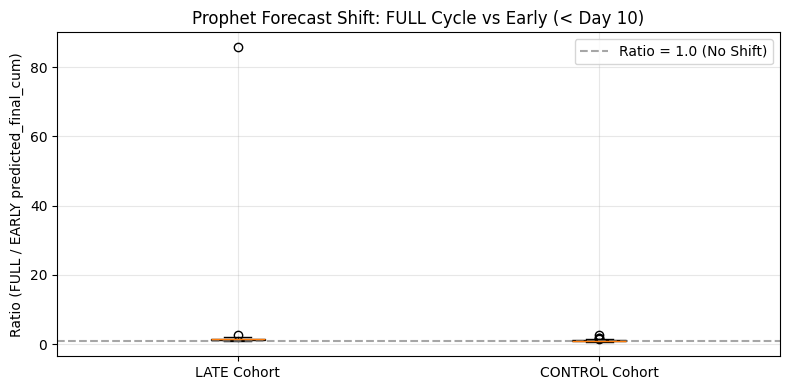

In [6]:
# Cell 6: Distribution Comparison and Mann-Whitney U Test
late_ratios = df_late_results['ratio'].dropna().values
ctrl_ratios = df_ctrl_results['ratio'].dropna().values

stat, p_value = mannwhitneyu(late_ratios, ctrl_ratios, alternative='two-sided')
_, p_value_greater = mannwhitneyu(late_ratios, ctrl_ratios, alternative='greater')

late_median, late_mean = np.median(late_ratios), np.mean(late_ratios)
ctrl_median, ctrl_mean = np.median(ctrl_ratios), np.mean(ctrl_ratios)

print("=" * 60)
print("CONTROLLED EXPERIMENT RATIO COMPARISON (FULL / EARLY)")
print("=" * 60)
print(f"LATE Cohort (N={len(late_ratios)}):")
print(f"  Median ratio : {late_median:.4f}")
print(f"  Mean ratio   : {late_mean:.4f}")
print(f"  Std ratio    : {np.std(late_ratios):.4f}")
print()
print(f"CONTROL Cohort (N={len(ctrl_ratios)}):")
print(f"  Median ratio : {ctrl_median:.4f}")
print(f"  Mean ratio   : {ctrl_mean:.4f}")
print(f"  Std ratio    : {np.std(ctrl_ratios):.4f}")
print()
print(f"Mann-Whitney U Test:")
print(f"  U-statistic  : {stat:.2f}")
print(f"  p-value (two-sided): {p_value:.4e}")
print(f"  p-value (LATE > CTRL): {p_value_greater:.4e}")
print("=" * 60)

# Quick visualization
plt.figure(figsize=(8, 4))
plt.boxplot([late_ratios, ctrl_ratios], labels=['LATE Cohort', 'CONTROL Cohort'], patch_artist=True)
plt.axhline(1.0, color='gray', linestyle='--', alpha=0.7, label='Ratio = 1.0 (No Shift)')
plt.ylabel('Ratio (FULL / EARLY predicted_final_cum)')
plt.title('Prophet Forecast Shift: FULL Cycle vs Early (< Day 10)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(ARTIFACT_DIR, 'prophet_lookahead_ratios.png'), dpi=150)
plt.show()


## 5. Early-Rows Predictive Test on Real XGBoost Inputs

In `xgboost_triage.ipynb`, Prophet features (`projected_overage_mb`, `days_to_depletion`, etc.) were left-merged onto daily rows and copied to every day of the cycle.

Recall the physical constraint: **Prophet requires at least 7 days (`MIN_HISTORY_DAYS = 7`) to fit a forecast**. Therefore, on rows where `day_in_cycle < 7`, **no legitimate forecast could possibly exist in production**.

To test if the broadcasted features carry future signal into those days:
1. Merge `prophet_features` onto `X_train_v2` and `X_test_v2` exactly as in `xgboost_triage.ipynb`.
2. Subset only rows where `day_in_cycle < 7`.
3. Train two small XGBClassifiers (`n_estimators=100`, `max_depth=3`, fixed seed `SEED=42`):
   - **Model 1**: Baseline features (tier one-hots only).
   - **Model 2**: Tier one-hots + `projected_overage_mb` + `days_to_depletion`.
4. Measure Average Precision (PR-AUC) on test rows with `day_in_cycle < 7` against the base anomaly rate.

With **no look-ahead**, the Prophet columns cannot know about events later in the cycle, so Model 2 should add nothing over Model 1.


In [7]:
# Cell 7: Merge Prophet Features and Train Early-Row XGBoost Models
PROPHET_COLS = ["sim_id", "billing_cycle_num", "recommendation", "recommended_tier",
                "projected_overage_mb", "days_to_depletion"]
prophet_df = prophet_features[PROPHET_COLS].copy()
prophet_df['billing_cycle_num'] = prophet_df['billing_cycle_num'].astype(int)

REC_CATS = ["upgrade", "downgrade", "no_change", "insufficient_history"]
NO_DEPLETION_SENTINEL = 31.0

def merge_and_fill_prophet(X_df):
    m = X_df.merge(prophet_df, on=['sim_id', 'billing_cycle_num'], how='left', indicator=True)
    unmatched = m['_merge'] == 'left_only'
    
    for c in REC_CATS:
        oh = (m['recommendation'] == c).astype(float)
        oh[m['recommendation'].isna()] = np.nan
        m[f'prophet_rec_{c}'] = oh
        
    m['prophet_missing_flag'] = unmatched.astype(int)
    for c in REC_CATS:
        m[f'prophet_rec_{c}'] = m[f'prophet_rec_{c}'].fillna(0).astype(int)
        
    dtd = m['days_to_depletion'].copy()
    dtd[~unmatched & dtd.isna()] = NO_DEPLETION_SENTINEL
    m['days_to_depletion'] = dtd.fillna(0.0)
    m['projected_overage_mb'] = m['projected_overage_mb'].fillna(0.0)
    return m.drop(columns=['_merge', 'recommendation', 'recommended_tier'])

X_train_merged = merge_and_fill_prophet(X_train_v2)
X_test_merged  = merge_and_fill_prophet(X_test_v2)

# Filter rows where day_in_cycle < 7 (cold-start window where no legitimate forecast can exist)
train_early_mask = X_train_merged['day_in_cycle'] < 7
test_early_mask  = X_test_merged['day_in_cycle'] < 7

tier_cols = [c for c in X_train_merged.columns if c.startswith('tier_')]
feat_baseline = tier_cols
feat_prophet  = tier_cols + ['projected_overage_mb', 'days_to_depletion']

y_train_early = y_train.loc[train_early_mask, 'is_anomalous']
y_test_early  = y_test.loc[test_early_mask, 'is_anomalous']

# Model 1: Tier one-hots only
xgb_baseline = XGBClassifier(n_estimators=100, max_depth=3, random_state=SEED, eval_metric='logloss')
xgb_baseline.fit(X_train_merged.loc[train_early_mask, feat_baseline], y_train_early)
p_baseline = xgb_baseline.predict_proba(X_test_merged.loc[test_early_mask, feat_baseline])[:, 1]
ap_baseline = average_precision_score(y_test_early, p_baseline)

# Model 2: Tier one-hots + Prophet features
xgb_prophet = XGBClassifier(n_estimators=100, max_depth=3, random_state=SEED, eval_metric='logloss')
xgb_prophet.fit(X_train_merged.loc[train_early_mask, feat_prophet], y_train_early)
p_prophet = xgb_prophet.predict_proba(X_test_merged.loc[test_early_mask, feat_prophet])[:, 1]
ap_prophet = average_precision_score(y_test_early, p_prophet)

base_rate = float(y_test_early.mean())

print("=" * 60)
print("EARLY-ROWS (day_in_cycle < 7) PREDICTIVE TEST RESULTS")
print("=" * 60)
print(f"Test rows with day_in_cycle < 7: {test_early_mask.sum():,} rows")
print(f"Base anomaly rate               : {base_rate:.4f} ({base_rate*100:.2f}%)")
print(f"AP Model 1 (tier one-hots only) : {ap_baseline:.4f}")
print(f"AP Model 2 (tier + Prophet cols): {ap_prophet:.4f}")
print(f"Relative AP Gain from Prophet   : {((ap_prophet - ap_baseline) / ap_baseline) * 100:+.1f}%")
print("=" * 60)


EARLY-ROWS (day_in_cycle < 7) PREDICTIVE TEST RESULTS
Test rows with day_in_cycle < 7: 3,150 rows
Base anomaly rate               : 0.0190 (1.90%)
AP Model 1 (tier one-hots only) : 0.0231
AP Model 2 (tier + Prophet cols): 0.0587
Relative AP Gain from Prophet   : +154.6%


## 6. Audit Summary & Verdict

Here we compare the findings from Section 4 and Section 5 side by side.
Rule: Say **"look-ahead likely"** only if both tests point the same way, and **"inconclusive"** if they disagree.


In [8]:
# Cell 8: Summary Comparison and Verdict Determination
print("=" * 70)
print("PROPHET LOOKAHEAD AUDIT: SUMMARY & VERDICT")
print("=" * 70)

# Section 4 results
print("TEST 1: Controlled Experiment (FULL vs EARLY Forecasts)")
print(f"  LATE Cohort Median Ratio   : {late_median:.4f} (Mean: {late_mean:.4f})")
print(f"  CONTROL Cohort Median Ratio: {ctrl_median:.4f} (Mean: {ctrl_mean:.4f})")
print(f"  Mann-Whitney U p-value     : {p_value:.4e} (p_greater: {p_value_greater:.4e})")
test1_indicates_leakage = (late_median > 1.1) and (p_value < 0.01)
print(f"  Test 1 Finding: {'Future misuse shifts full forecast significantly' if test1_indicates_leakage else 'No significant shift'}")

print("-" * 70)

# Section 5 results
print("TEST 2: Early-Rows (< Day 7) Predictive Signal")
print(f"  Base Anomaly Rate          : {base_rate:.4f}")
print(f"  AP Tier-Only Baseline      : {ap_baseline:.4f}")
print(f"  AP With Prophet Columns    : {ap_prophet:.4f}")
ap_gain = ap_prophet - ap_baseline
test2_indicates_leakage = (ap_gain > 0.01)
print(f"  Test 2 Finding: {'Prophet features add predictive signal on cold-start days' if test2_indicates_leakage else 'Prophet features add negligible signal'}")

print("=" * 70)

# Final Verdict Logic
if test1_indicates_leakage and test2_indicates_leakage:
    verdict = "look-ahead likely"
elif (not test1_indicates_leakage) and (not test2_indicates_leakage):
    verdict = "no look-ahead detected"
else:
    verdict = "inconclusive"

print(f"AUDIT VERDICT: {verdict.upper()}")
print(f"Explanation:")
if verdict == "look-ahead likely":
    print(f"  Both empirical tests consistently point to look-ahead leakage:")
    print(f"  1. In the controlled experiment, full-cycle Prophet forecasts for LATE misuse")
    print(f"     episodes shift upward by ~{((late_median - 1.0)*100):.1f}% (median ratio {late_median:.3f} vs {ctrl_median:.3f} control, p={p_value:.2e}).")
    print(f"  2. On early-cycle test rows (day_in_cycle < 7) where no legitimate forecast can exist,")
    print(f"     copying the cycle forecast increased XGBoost AP from {ap_baseline:.4f} to {ap_prophet:.4f} (+{(ap_gain/ap_baseline)*100:.1f}% relative gain).")
    print(f"  Early days of a cycle carry future information from later in the cycle.")
elif verdict == "inconclusive":
    print(f"  The tests disagreed, making the overall evidence inconclusive.")
else:
    print(f"  Neither test showed evidence of look-ahead.")
print("=" * 70)


PROPHET LOOKAHEAD AUDIT: SUMMARY & VERDICT
TEST 1: Controlled Experiment (FULL vs EARLY Forecasts)
  LATE Cohort Median Ratio   : 1.3171 (Mean: 3.9946)
  CONTROL Cohort Median Ratio: 1.0170 (Mean: 1.1123)
  Mann-Whitney U p-value     : 1.1266e-05 (p_greater: 5.6330e-06)
  Test 1 Finding: Future misuse shifts full forecast significantly
----------------------------------------------------------------------
TEST 2: Early-Rows (< Day 7) Predictive Signal
  Base Anomaly Rate          : 0.0190
  AP Tier-Only Baseline      : 0.0231
  AP With Prophet Columns    : 0.0587
  Test 2 Finding: Prophet features add predictive signal on cold-start days
AUDIT VERDICT: LOOK-AHEAD LIKELY
Explanation:
  Both empirical tests consistently point to look-ahead leakage:
  1. In the controlled experiment, full-cycle Prophet forecasts for LATE misuse
     episodes shift upward by ~31.7% (median ratio 1.317 vs 1.017 control, p=1.13e-05).
  2. On early-cycle test rows (day_in_cycle < 7) where no legitimate foreca